<a href="https://colab.research.google.com/github/julihdez36/Statistics/blob/main/Estadistica4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelos probabilísticos

En general se trata de analizar una determinada variable X en los individuos de una población. Ésta puede ser unidimensional o multidimensional. En concreto, se procura estudiar alguna característica, como su media, tratando de inferir un valor para dicho parámetro poblacional, medienta un contraste de hipótesis, entre dos conjiutno de posibles valores del parametro.

La inferencia dependera de la distribucion de probabilidad o modelo probabilistico supuesto como ley que rige el fenomeno aleatorio en estudio.

## Distribución de probabilidad

Supongamos una población de 50 minllones de individuos. La selección aleatoria de los individuos de esta poblacion puede formalizarse mediaante un espacio probabilistico $(\Omega, \mathcal{A}, P)$ en sonde el espacio muesral esté constituido por los individuod de la población
$$
\Omega = \{w_{1}, \dots , w_{5e^6}\}
$$

tal que sobre el conunto $\mathcal{A}$ de sucesos está definida una probabiidad P, de forma que todos los sucesos elementales dean equiprobables: Modelo uniforme.

Habitualment estaremos interesados no en el espacio probabilistico sino en una transformacion suya (el nivel II) tal que no solo nos de los valores de las caracteristicas en estudio para los individuos de la poblacion.

$$
X: \Omega \rightarrow \mathbb{R}  
$$

sino que conserve la probabilidad $P$, aglutinando la nueva $P_{X}$ las probabilidades de los sucesos elementales $w_{i}$ a los que corresponda el mismo valor mediante $X$

$$
P_{X}(A) = P\{w \in \Omega: X(w) \in A\} = P\{X^{-1}(A)\}
$$

La función X recibe el nombre de **variable aleatoria** y $P_{X}$ el de su **distribución de probabilidad**.

### Ejemplo:

Consideremos el experimento aleatorio del lanzamiento de un dado. El espacio muestral es el número de puntos que aparecen en la cara superior, sobre el cual X realiza una tranformación en $\mathbb{R}$

$$
X(\Omega) = \{1,2,3,4,5,6\} \subset \mathbb{R}
$$

Esta transofrmación conserva la misma estructura probabilística del espacio original.

Consideremos el suceso A = "sacar un número par", por tanto:

$$
A = \{2,4,6\} \subset \mathbb{R}
$$

la probabilidad del suceso A sería, la cual se justifica por la propiedad de aditividad numerable, o tercer axioma de Kolmogorov:

$$
P_{X}(A) = P\{2,4,6\} = \frac{3}{6} = \frac{1}{2}
$$

In [ ]:
# Definimos el espacio muestral

Omega <- c("cara_1", "cara_2", "cara_3", "cara_4", "cara_5", "cara_6")

# Definimos la variable aleatoria X: Omega --> R

X_func <- setNames(1:6, Omega)

# Identificamos los sucesos elementales del evento A = "par"
E2 <- "cara_2"
E4 <- "cara_4"
E6 <- "cara_6"

# Probabilidades teóricas P(E_i) en el espacio original (distribucion uniforme)
P_E2 <- 1/6
P_E4 <- 1/6
P_E6 <- 1/6

# Por axioma 3 de Kolmogorov
P_X_par_teorica <- P_E2 + P_E4 + P_E6
P_X_par_teorica

[1] 0.5

Para corroborar este resultado podemos realizar una simulación monte carlo

In [ ]:
set.seed(42)
n_lanzamientos <- 100000

# Simulamos n lanzamientos en Omega
muestra_Omega <- sample(Omega, size = n_lanzamientos, replace = TRUE)

# Aplicamos la variable aleatoria X a la muestra para pasar a R
muestra_X <- X_func[muestra_Omega]

# Evaluamos las condiciones elementales
es_2 <- muestra_X == 2
es_4 <- muestra_X == 4
es_6 <- muestra_X == 6

# Unimos con OR lógico (equivalente a la Unión de conjuntos disjuntos)
es_par <- es_2 | es_4 | es_6

# Calculamos frecuencias relativas (Aproximación empírica a P)
P_empirica_2   <- mean(es_2)
P_empirica_4   <- mean(es_4)
P_empirica_6   <- mean(es_6)
P_empirica_par <- mean(es_par)

# Imprimimos resultados empíricos
cat("--- RESULTADOS DE LA SIMULACIÓN (n =", n_lanzamientos, ") ---\n")
cat("P_X({2}) empírica: ", P_empirica_2, "\n")
cat("P_X({4}) empírica: ", P_empirica_4, "\n")
cat("P_X({6}) empírica: ", P_empirica_6, "\n")
cat("Suma de probabilidades individuales: ", P_empirica_2 + P_empirica_4 + P_empirica_6, "\n")
cat("P_X({2, 4, 6}) evaluada directamente: ", P_empirica_par, "\n")

--- RESULTADOS DE LA SIMULACIÓN (n = 1e+05 ) ---
P_X({2}) empírica:  0.16697 
P_X({4}) empírica:  0.16697 
P_X({6}) empírica:  0.16458 
Suma de probabilidades individuales:  0.49852 
P_X({2, 4, 6}) evaluada directamente:  0.49852 


Evidentemente, sobre un  espacio probabilistico es posible definir muchas variables aleatorias. Cuando se considran a lavez varias de ellas, de forma que en los individus delapoblación seobservab varioscaracteresm queda constituido loqie se denimmina una **variable aleatoria multidimensional** o **vector aleatorio** $X = (X_{1}, \dots , X_{P})$.

Nótese que nada impide que los sucesos elementales del espacio muestral sean números reales, por lo que, en ese caso, la aplicación identidad es la variable aleatoria natural a considerar.  

Asociado a toda variable aleatoria existe una funcion $F(x)$ denominada **funcion de distibución** de $X$, la cual va midiendo la probabilidad acumulada por $X$ hasta el punto $x$, esdecir

$$
F(X) = P \{w \in \Omega: X(w) \leq x\}
$$

Esta función tiene la propiedad de caracterizar la **distribución de probabilidad** de $X$, $Px$. Es decir, a partir de una de ellas se obtiene la otra, siendo habitualmente más cómodo trabajar con la función de distribubión.

Si una variable aleatoria toma valores aislados se denomina discreta. Si por el contrario puede tomar cualquier valor de un intervalo, recibe el nombre de continua.Se aplican analogamente en distribuciones.


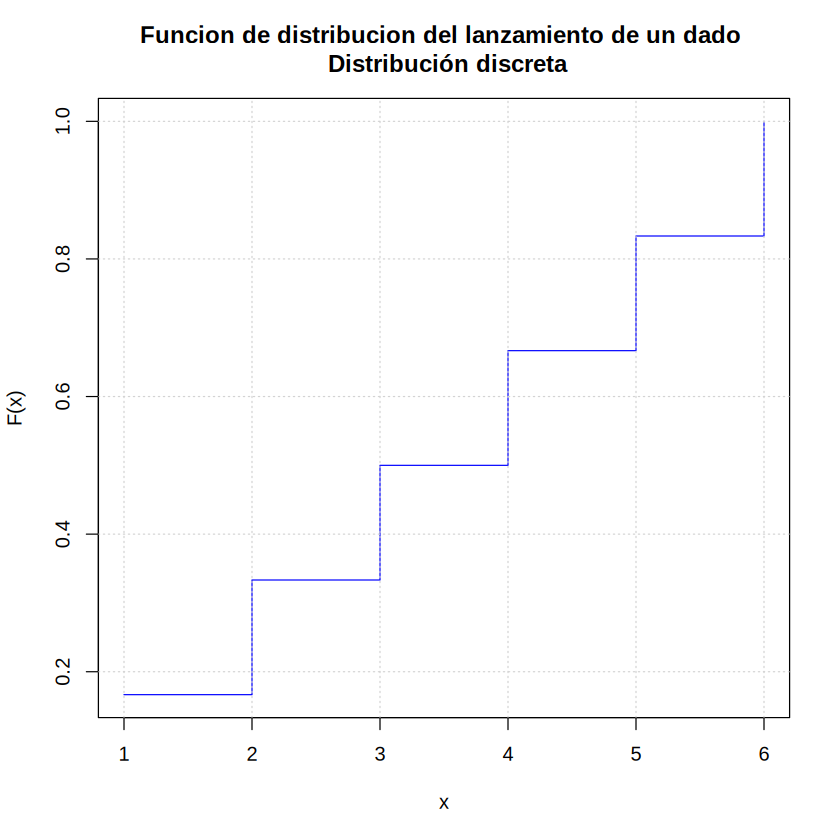

In [ ]:
# Valores posibles del lanzamiento
x <- 1:6

# Probabilidades de cada resultado
p <- rep(1/6, 6)

# Funcion de distribucion acumulada
F <- cumsum(p)

# Graficar la funcion de distribucion
plot(
  x, F,
  type = "s",
  main = "Funcion de distribucion del lanzamiento de un dado \n Distribución discreta",
  xlab = "x",
  ylab = "F(x)",
  col = "blue"
)

# Agregar una cuadricula
grid()


A partir de las propiedades de las probabilidades se puede deducir que las funciones de distribución son:

1. No decrecientes.
2. Continuas por la derecha.
3. $\lim_{x \rightarrow -\infty} F(x) = 0$ y $ \lim_{x \rightarrow -\infty} F(x) = 1$

Las variables aleatoris discretas tienenasociada una **función de masa** $PX(x)$, la cual da la probabilidad de los valores aislados de dicha variable aleatoria:
$$
PX(x) =
$$

